<a href="https://colab.research.google.com/github/JuanMauwu/air-quality-prediction-analysis/blob/main/notebooks/Exploraci%C3%B3n_inicial_dataset_Dhaka_AQI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exploración inicial Dataset**
Este notebook realiza una exploración inicial del conjunto de datos Dhaka Air Quality Index (AQI), descargado desde Kaggle. Se examina su estructura general, dimensiones, variables y tipos de datos, así como las características principales de cada columna mediante estadísticas descriptivas y el análisis de valores únicos. Además, se identifican posibles valores faltantes y registros duplicados, con el propósito de conocer la calidad y composición de los datos, comprender las variables disponibles y establecer una base para las siguientes etapas del análisis y preprocesamiento.

In [50]:
#Importacion de librerías

import pandas as pd
from pathlib import Path
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [6]:
#descargar el dataset desde Kaggle
ruta_dataset = kagglehub.dataset_download(
    "nasiruddin123/dhaka-air-quality-index-dataset",
    output_dir="/content/kaggle_data"
)

print("Dataset descargado en:", ruta_dataset)

Using Colab cache for faster access to the 'dhaka-air-quality-index-dataset' dataset.
Dataset descargado en: /kaggle/input/dhaka-air-quality-index-dataset


In [7]:
#observamos que archivos contiende el dataset
ruta = Path(ruta_dataset)
print("Archivos encontrados:\n")

for archivo in ruta.rglob("*"):
    if archivo.is_file():
        print(archivo.name, "|", archivo.suffix, "|",
              round(archivo.stat().st_size / (1024**2), 2), "MB")

Archivos encontrados:

dhaka_air_quality_no_pollutants.csv | .csv | 0.71 MB
dhaka_air_quality_no_pollutants.xlsx | .xlsx | 0.6 MB


In [8]:

#definimos como df al .csv que contiene el conjunto de datos y lo visualizamos
df = pd.read_csv("/content/kaggle_data/dhaka_air_quality_no_pollutants.csv")
display(df.head())

,area,station_type,aqi,aqi_category,temperature_c,humidity_pct,wind_speed_kmh,wind_direction,rainfall_mm,pressure_hpa,visibility_km,traffic_level,construction_nearby
0,Mirpur,residential,199,Unhealthy,24.0,65,3.2,W,0.0,1011.6,6.6,High,No
1,Jatrabari,industrial,114,Unhealthy for Sensitive Groups,33.2,100,3.8,S,0.0,1000.0,9.4,Severe,Yes
2,Motijheel,roadside,89,Moderate,30.6,83,8.3,E,11.5,1002.9,11.5,High,Yes
3,Mohammadpur,residential,181,Unhealthy,14.7,66,4.9,E,0.0,1009.2,7.0,Severe,No
4,Mohammadpur,residential,178,Unhealthy,25.2,53,6.9,N,0.0,1018.7,8.8,Low,No


In [9]:
print("Dimensiones del dataset:", df.shape) #observamos las dimensiones del dataset
print("\nColumnas:") #mostramos las variables
print(df.columns.tolist())

Dimensiones del dataset: (10000, 13)

Columnas:
['area', 'station_type', 'aqi', 'aqi_category', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'wind_direction', 'rainfall_mm', 'pressure_hpa', 'visibility_km', 'traffic_level', 'construction_nearby']


In [10]:
#revisamos el tipo de dato de cada variable y demás información
print("\nInformación general:")
df.info()


Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area                 10000 non-null  object 
 1   station_type         10000 non-null  object 
 2   aqi                  10000 non-null  int64  
 3   aqi_category         10000 non-null  object 
 4   temperature_c        10000 non-null  float64
 5   humidity_pct         10000 non-null  int64  
 6   wind_speed_kmh       10000 non-null  float64
 7   wind_direction       10000 non-null  object 
 8   rainfall_mm          10000 non-null  float64
 9   pressure_hpa         10000 non-null  float64
 10  visibility_km        10000 non-null  float64
 11  traffic_level        10000 non-null  object 
 12  construction_nearby  10000 non-null  object 
dtypes: float64(5), int64(2), object(6)
memory usage: 1015.8+ KB


In [11]:
#revisamos información general de cada variable en especifico
for columna in df.columns:
    print(f"\n{'=' * 50}")
    print(f"Variable: {columna}")
    print(f"Tipo de dato: {df[columna].dtype}")
    print(f"Valores únicos: {df[columna].nunique()}")

    if pd.api.types.is_numeric_dtype(df[columna]):
        print(f"Mínimo: {df[columna].min()}")
        print(f"Máximo: {df[columna].max()}")
        print(f"Media: {df[columna].mean():.2f}")
        print(f"Desviación estándar: {df[columna].std():.2f}")
    else:
        print("Categorías o valores registrados:")
        print(df[columna].value_counts(dropna=False).to_dict())


Variable: area
Tipo de dato: object
Valores únicos: 12
Categorías o valores registrados:
{'Mirpur': 875, 'Mohammadpur': 872, 'Tejgaon': 869, 'Baridhara': 865, 'Gulshan': 853, 'Hazaribagh': 834, 'Jatrabari': 828, 'Old Dhaka': 815, 'Uttara': 806, 'Motijheel': 802, 'Agargaon': 791, 'Dhanmondi': 790}

Variable: station_type
Tipo de dato: object
Valores únicos: 4
Categorías o valores registrados:
{'residential': 3406, 'roadside': 3198, 'industrial': 2531, 'background': 865}

Variable: aqi
Tipo de dato: int64
Valores únicos: 433
Mínimo: 22
Máximo: 500
Media: 161.34
Desviación estándar: 78.11

Variable: aqi_category
Tipo de dato: object
Valores únicos: 6
Categorías o valores registrados:
{'Unhealthy': 3735, 'Moderate': 2293, 'Unhealthy for Sensitive Groups': 1799, 'Very Unhealthy': 1559, 'Hazardous': 489, 'Good': 125}

Variable: temperature_c
Tipo de dato: float64
Valores únicos: 288
Mínimo: 6.5
Máximo: 39.3
Media: 26.42
Desviación estándar: 5.61

Variable: humidity_pct
Tipo de dato: int64
V

In [12]:
#revisamos posibles valores faltantes
print("\nValores faltantes por columna:")
display(df.isnull().sum().to_frame("Valores faltantes"))


Valores faltantes por columna:


,Valores faltantes
area,0
station_type,0
aqi,0
aqi_category,0
temperature_c,0
humidity_pct,0
wind_speed_kmh,0
wind_direction,0
rainfall_mm,0
pressure_hpa,0


In [13]:
#revisamos posibles filas duplicadas
print("\nFilas duplicadas:", df.duplicated().sum())


Filas duplicadas: 0


In [14]:
#imprimimos estadisticas descriptivas generales del conjunto de datos
print("\nEstadísticas descriptivas:")
display(df.describe(include="all").T)


Estadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
area,10000,12,Mirpur,875,NaN,NaN,NaN,NaN,NaN,NaN,NaN
station_type,10000,4,residential,3406,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aqi,10000.0,NaN,NaN,NaN,161.3423,78.105783,22.0,103.0,159.0,191.0,500.0
aqi_category,10000,6,Unhealthy,3735,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_c,10000.0,NaN,NaN,NaN,26.42003,5.606521,6.5,22.3,28.2,30.6,39.3
humidity_pct,10000.0,NaN,NaN,NaN,75.8606,10.556482,41.0,68.0,76.0,83.0,100.0
wind_speed_kmh,10000.0,NaN,NaN,NaN,7.03191,4.928873,0.3,3.5,5.9,9.4,39.7
wind_direction,10000,8,S,1742,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rainfall_mm,10000.0,NaN,NaN,NaN,2.06119,6.427811,0.0,0.0,0.0,0.0,85.8
pressure_hpa,10000.0,NaN,NaN,NaN,1008.60347,5.776719,993.5,1003.8,1008.8,1013.5,1023.3


#**Conclusiones de la exploración inicial**

La exploración inicial permitió identificar que el conjunto de datos Dhaka Air Quality Index (AQI) contiene 10.000 registros y 13 variables, que incluyen información geográfica, características de las estaciones de monitoreo, condiciones meteorológicas, niveles de tráfico y calidad del aire. No se encontraron valores faltantes ni filas duplicadas, por lo que el conjunto presenta buenas condiciones iniciales de integridad.

En cuanto a la variable objetivo `aqi`, se obtuvo un promedio de 161,34, con valores entre 22 y 500 y una desviación estándar de 78,11, lo que evidencia una variabilidad considerable en los niveles de calidad del aire registrados. Además, la categoría más frecuente fue *Unhealthy*, con 3.735 registros, mientras que *Good* presentó únicamente 125. Esta distribución muestra una mayor presencia de registros asociados con condiciones desfavorables de calidad del aire dentro del conjunto analizado.

Respecto a las demás variables, se identificaron 12 áreas, cuatro tipos de estaciones y diferentes condiciones ambientales y de actividad urbana. Entre las categorías registradas, predominan las estaciones residenciales, los niveles medios de tráfico y los registros sin construcciones cercanas. Estos resultados permiten reconocer las características generales de los datos y las variables potencialmente relevantes para el análisis.

En conclusión, el conjunto de datos cuenta con una estructura adecuada para continuar con el análisis exploratorio y la preparación de los datos.

#Fase de configuración

##1. Prepeparación y eliminación de data leakage

In [17]:
# Eliminamos 'aqi' (target) y 'aqi_category' (variable implícita de fuga)
X = df.drop(columns=['aqi', 'aqi_category'])
y = df['aqi']

# Identificar automáticamente columnas numéricas y categóricas
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

print(f"Variables numéricas a estandarizar (mean=0, std=1): {num_cols}")
print(f"Variables categóricas a aplicar One-Hot Encoding: {cat_cols}")

Variables numéricas a estandarizar (mean=0, std=1): ['temperature_c', 'humidity_pct', 'wind_speed_kmh', 'rainfall_mm', 'pressure_hpa', 'visibility_km']
Variables categóricas a aplicar One-Hot Encoding: ['area', 'station_type', 'wind_direction', 'traffic_level', 'construction_nearby']


## 2. Sseparación de train (80%) y test (20%)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

## 3. Pipeline de preprocesamiento

In [21]:
# Estandarización para numéricas (StandardScaler) + OneHotEncoder para categóricas
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

# 4. Estrategia de validación cruzada K-Fold (5 Folds)
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

#Entrenamiento de modelos


##**Modelo paramétrico:** Regresión lineal

In [37]:
pipeline_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

###Busqueda de los mejores hiperparámetros

In [38]:
# Malla de hiperparámetros
param_grid_lr = {
    'regressor__fit_intercept': [True, False],
    'regressor__positive': [True, False]
}

# Configuración del GridSearchCV (K=5)
grid_lr = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid_lr,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Entrenar modelo
grid_lr.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['temperature_c',
                                                                          'humidity_pct',
                                                                          'wind_speed_kmh',
                                                                          'rainfall_mm',
                                                                          'pressure_hpa',
                                                                          'visibility_km']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['area',
                                                                          'station_type',
                                                                          'wind_direction',
                                                                          'traffic_level',
                                                                          'construction_nearby'])])),
                                       ('regressor', LinearRegression())]),
             n_jobs=-1,
             param_grid={'regressor__fit_intercept': [True, False],
                         'regressor__positive': [True, False]},
             scoring='neg_root_mean_squared_error')

###Evaluación y visualización de resultados

In [39]:
# Mejor modelo y predicción
best_lr = grid_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test)

# Métricas de evaluación
metrics_lr = {
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lr)),
    'MAE': mean_absolute_error(y_test, y_pred_lr),
    'MedAE': median_absolute_error(y_test, y_pred_lr),
    'R2': r2_score(y_test, y_pred_lr)
}

print("=== MEJORES HIPERPARÁMETROS REGRESIÓN LINEAL ===")
print(grid_lr.best_params_)
print("\n=== MÉTRICAS REGRESIÓN LINEAL (TEST) ===")
for metric, val in metrics_lr.items():
    print(f"{metric}: {val:.4f}")

=== MEJORES HIPERPARÁMETROS REGRESIÓN LINEAL ===
{'regressor__fit_intercept': True, 'regressor__positive': False}

=== MÉTRICAS REGRESIÓN LINEAL (TEST) ===
RMSE: 30.3765
MAE: 22.0851
MedAE: 16.8920
R2: 0.8520


###Gráficas de resultados



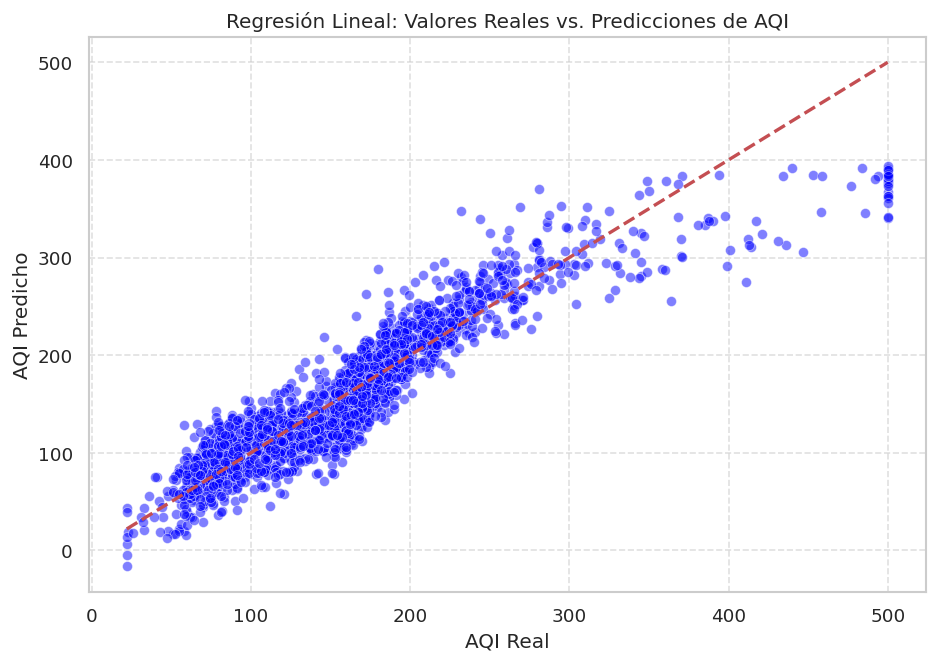

In [41]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=y_test, y=y_pred_lr, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Regresión Lineal: Valores Reales vs. Predicciones de AQI')
plt.xlabel('AQI Real')
plt.ylabel('AQI Predicho')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

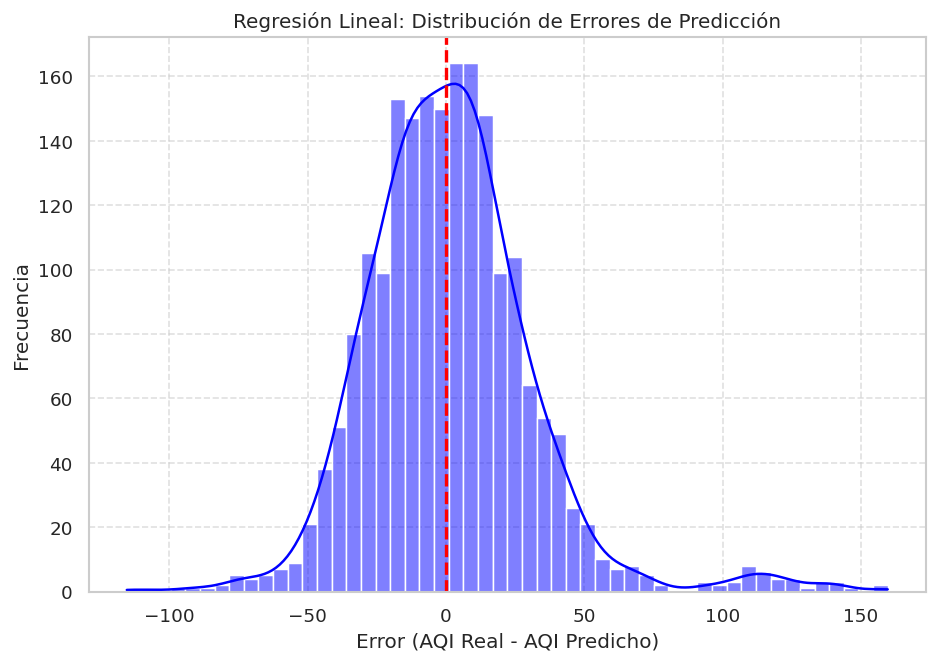

In [42]:
plt.figure(figsize=(9, 6))
residuals_lr = y_test - y_pred_lr
sns.histplot(residuals_lr, kde=True, color='blue')
plt.axvline(0, color='red', linestyle='--', lw=2)
plt.title('Regresión Lineal: Distribución de Errores de Predicción')
plt.xlabel('Error (AQI Real - AQI Predicho)')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

/tmp/ipykernel_1069/361467741.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=coefs, y=feature_names, palette='coolwarm')


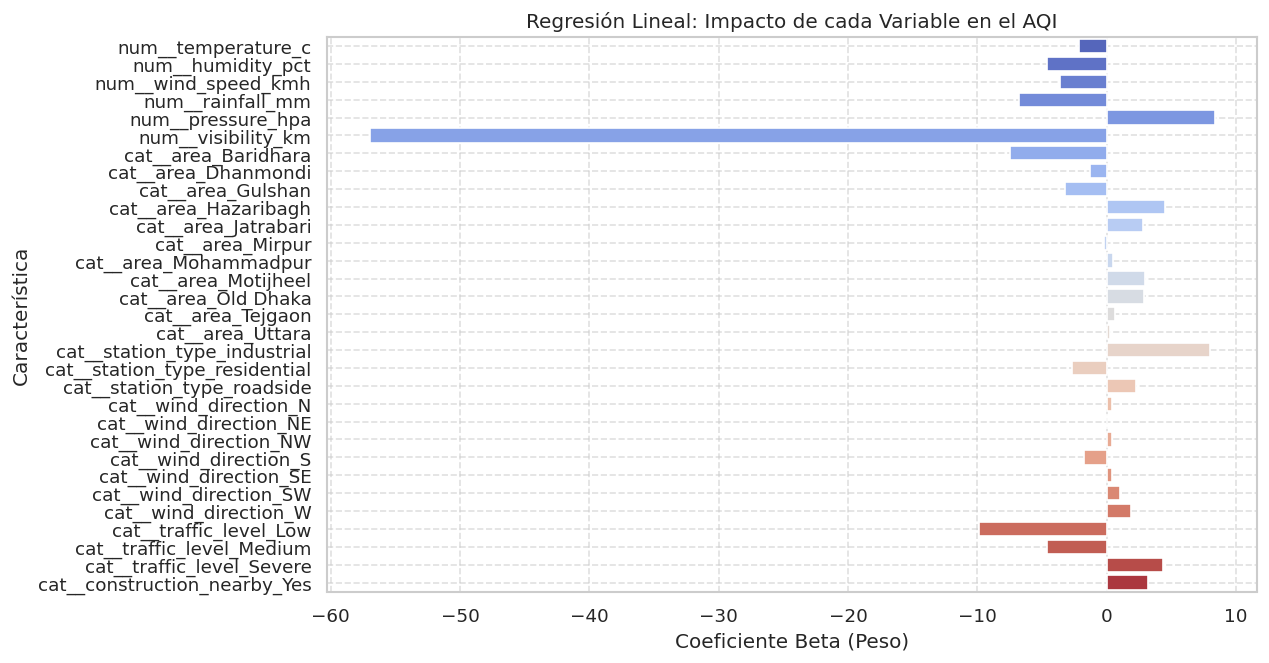

In [43]:
feature_names = best_lr.named_steps['preprocessor'].get_feature_names_out()
coefs = best_lr.named_steps['regressor'].coef_

plt.figure(figsize=(10, 6))
sns.barplot(x=coefs, y=feature_names, palette='coolwarm')
plt.title('Regresión Lineal: Impacto de cada Variable en el AQI')
plt.xlabel('Coeficiente Beta (Peso)')
plt.ylabel('Característica')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

##**Modelo No Paramétrico:** $k$-NN Regressor

In [44]:
pipeline_knn = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', KNeighborsRegressor())
])

###Busqueda de los mejores hiperparámetros

In [45]:
# Malla de hiperparámetros
param_grid_knn = {
    'regressor__n_neighbors': [3, 5, 7, 11, 15],
    'regressor__weights': ['uniform', 'distance'],
    'regressor__metric': ['euclidean', 'manhattan']
}

# Configuración del GridSearchCV (K=5)
grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Entrenar modelo
grid_knn.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['temperature_c',
                                                                          'humidity_pct',
                                                                          'wind_speed_kmh',
                                                                          'rainfall_mm',
                                                                          'pressure_hpa',
                                                                          'visibility_km']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['area',
                                                                          'station_type',
                                                                          'wind_direction',
                                                                          'traffic_level',
                                                                          'construction_nearby'])])),
                                       ('regressor', KNeighborsRegressor())]),
             n_jobs=-1,
             param_grid={'regressor__metric': ['euclidean', 'manhattan'],
                         'regressor__n_neighbors': [3, 5, 7, 11, 15],
                         'regressor__weights': ['uniform', 'distance']},
             scoring='neg_root_mean_squared_error')

###Evaluación y visualización de resultados

In [46]:
# Mejor modelo y predicción
best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test)

# Métricas de evaluación
metrics_knn = {
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_knn)),
    'MAE': mean_absolute_error(y_test, y_pred_knn),
    'MedAE': median_absolute_error(y_test, y_pred_knn),
    'R2': r2_score(y_test, y_pred_knn)
}

print("=== MEJORES HIPERPARÁMETROS k-NN ===")
print(grid_knn.best_params_)
print("\n=== MÉTRICAS k-NN (TEST) ===")
for metric, val in metrics_knn.items():
    print(f"{metric}: {val:.4f}")

=== MEJORES HIPERPARÁMETROS k-NN ===
{'regressor__metric': 'euclidean', 'regressor__n_neighbors': 15, 'regressor__weights': 'distance'}

=== MÉTRICAS k-NN (TEST) ===
RMSE: 29.2381
MAE: 21.0034
MedAE: 16.0140
R2: 0.8629


###Gráficas de resultados

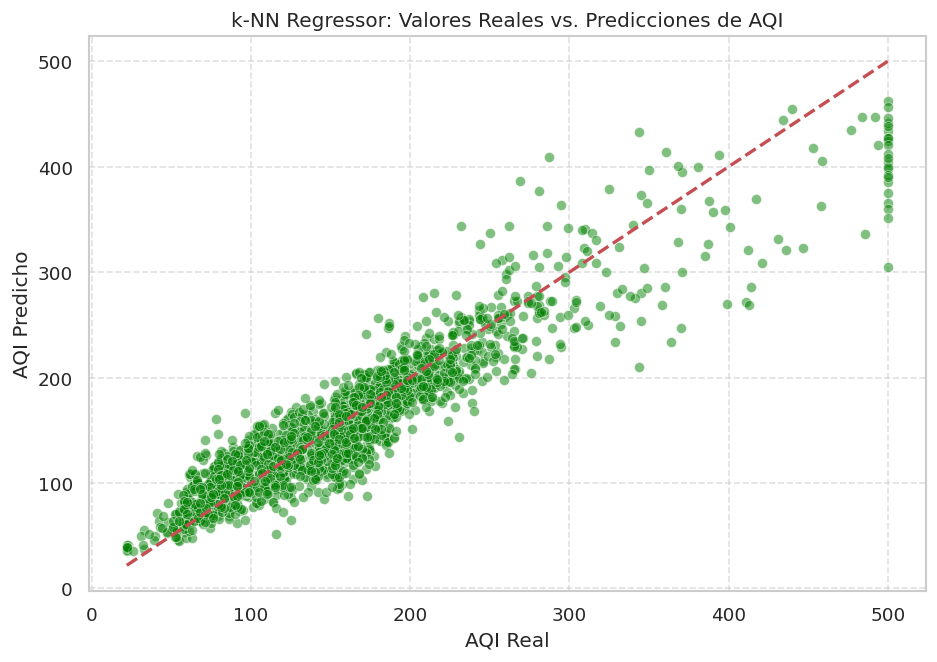

In [47]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=y_test, y=y_pred_knn, alpha=0.5, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('k-NN Regressor: Valores Reales vs. Predicciones de AQI')
plt.xlabel('AQI Real')
plt.ylabel('AQI Predicho')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

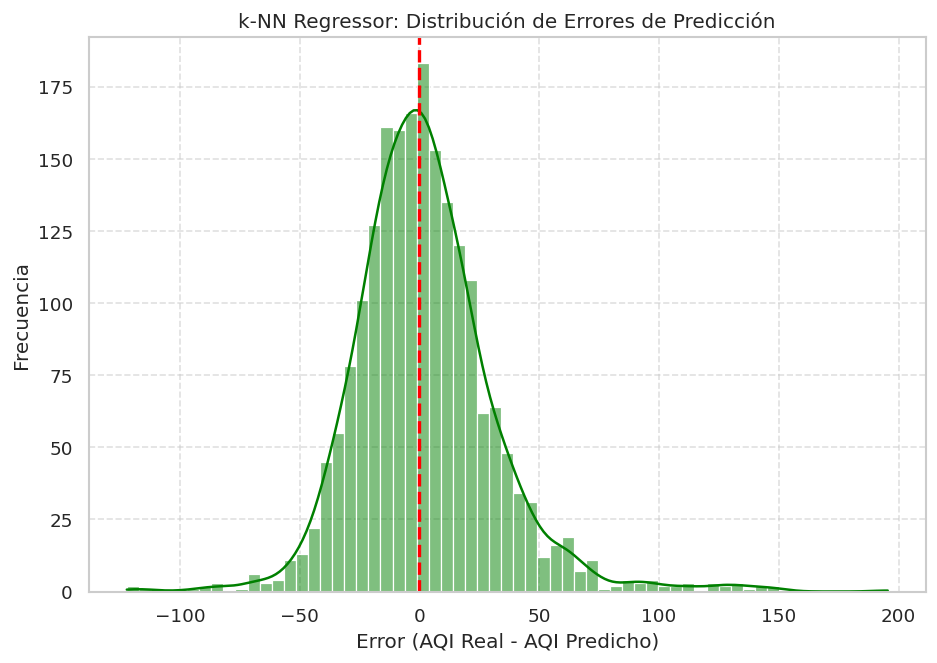

In [48]:
plt.figure(figsize=(9, 6))
residuals_knn = y_test - y_pred_knn
sns.histplot(residuals_knn, kde=True, color='green')
plt.axvline(0, color='red', linestyle='--', lw=2)
plt.title('k-NN Regressor: Distribución de Errores de Predicción')
plt.xlabel('Error (AQI Real - AQI Predicho)')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

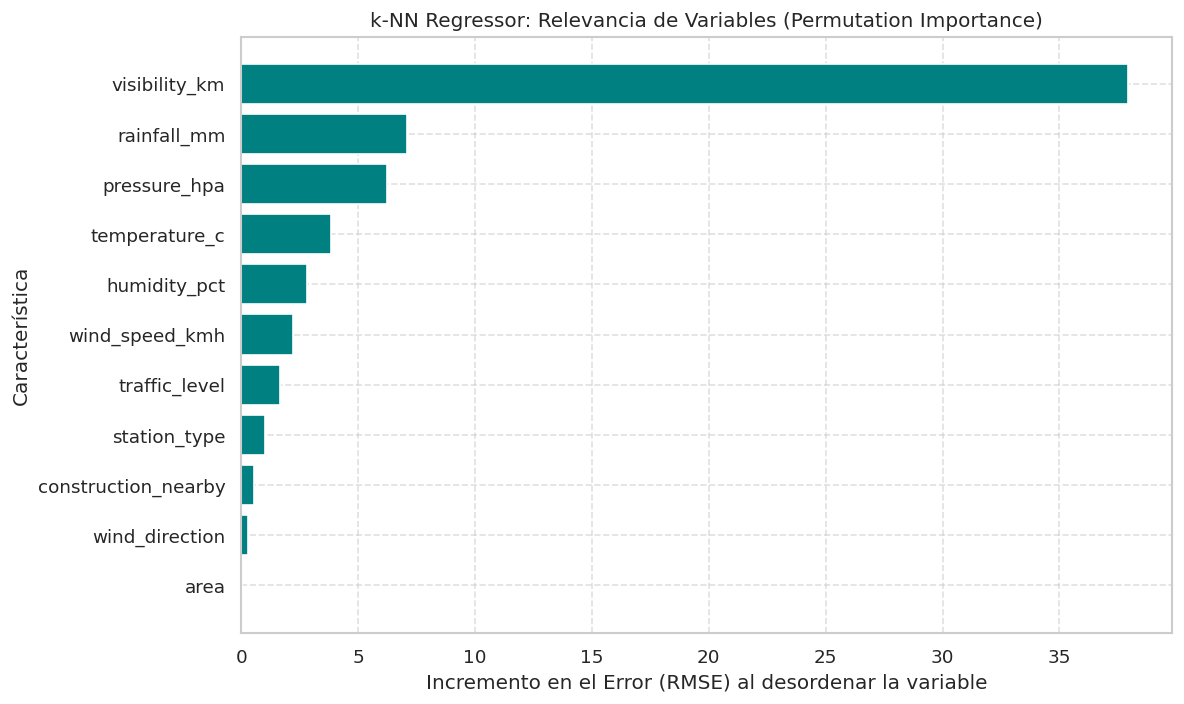

In [49]:
from sklearn.inspection import permutation_importance

# 1. Calcular la importancia por permutación sobre el conjunto de test
result = permutation_importance(
    best_knn, X_test, y_test,
    scoring='neg_root_mean_squared_error',
    n_repeats=10,
    random_state=42
)

# 2. Organizar los resultados en orden descendente
sorted_importances_idx = result.importances_mean.argsort()
feature_names = X_test.columns

# 3. Graficar de forma individual
plt.figure(figsize=(10, 6))
plt.barh(feature_names[sorted_importances_idx], result.importances_mean[sorted_importances_idx], color='teal')
plt.title('k-NN Regressor: Relevancia de Variables (Permutation Importance)')
plt.xlabel('Incremento en el Error (RMSE) al desordenar la variable')
plt.ylabel('Característica')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

##**Ensamble de Árboles:** Random Forest Regressorr

In [22]:
pipeline_rf = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestRegressor(random_state=42))
])

###Busqueda de los mejores hiperparámetros

In [25]:
# Malla de hiperparámetros
param_grid_rf = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [10, 15, 25],
    'model__min_samples_split': [2, 5, 10]
}

# Búsqueda en Malla
grid_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=cv_strategy,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    return_train_score=True,
    verbose=2
)

print("Entrenando Random Forest con GridSearchCV...")
grid_rf.fit(X_train, y_train)

Entrenando Random Forest con GridSearchCV...
Fitting 5 folds for each of 27 candidates, totalling 135 fits


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['temperature_c',
                                                                          'humidity_pct',
                                                                          'wind_speed_kmh',
                                                                          'rainfall_mm',
                                                                          'pressure_hpa',
                                                                          'visibility_km']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['area',
                                                                          'station_type',
                                                                          'wind_direction',
                                                                          'traffic_level',
                                                                          'construction_nearby'])])),
                                       ('model',
                                        RandomForestRegressor(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__max_depth': [10, 15, 25],
                         'model__min_samples_split': [2, 5, 10],
                         'model__n_estimators': [50, 100, 200]},
             return_train_score=True, scoring='neg_root_mean_squared_error',
             verbose=2)

###Evaluación y visualización de resultados

In [26]:
best_rf = grid_rf.best_estimator_
y_pred_test = best_rf.predict(X_test)

mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
medae_test = median_absolute_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

best_idx = grid_rf.best_index_
val_rmse_mean = -grid_rf.cv_results_['mean_test_score'][best_idx]
val_rmse_std = grid_rf.cv_results_['std_test_score'][best_idx]

print("\n" + "="*50)
print(" RESULTADOS RANDOM FOREST ")
print("="*50)
print(f"Mejores Hiperparámetros: {grid_rf.best_params_}")
print(f"Validación RMSE (5-Fold CV): {val_rmse_mean:.4f} ± {val_rmse_std:.4f}")
print(f"Test MAE: {mae_test:.4f}")
print(f"Test RMSE: {rmse_test:.4f}")
print(f"Test MedAE: {medae_test:.4f}")
print(f"Test R² Score: {r2_test:.4f}")


 RESULTADOS RANDOM FOREST 
Mejores Hiperparámetros: {'model__max_depth': 15, 'model__min_samples_split': 10, 'model__n_estimators': 200}
Validación RMSE (5-Fold CV): 25.8369 ± 1.0158
Test MAE: 18.6653
Test RMSE: 26.0310
Test MedAE: 14.1585
Test R² Score: 0.8913


###Gráficas de resultados

In [31]:
# Estilo visual general
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

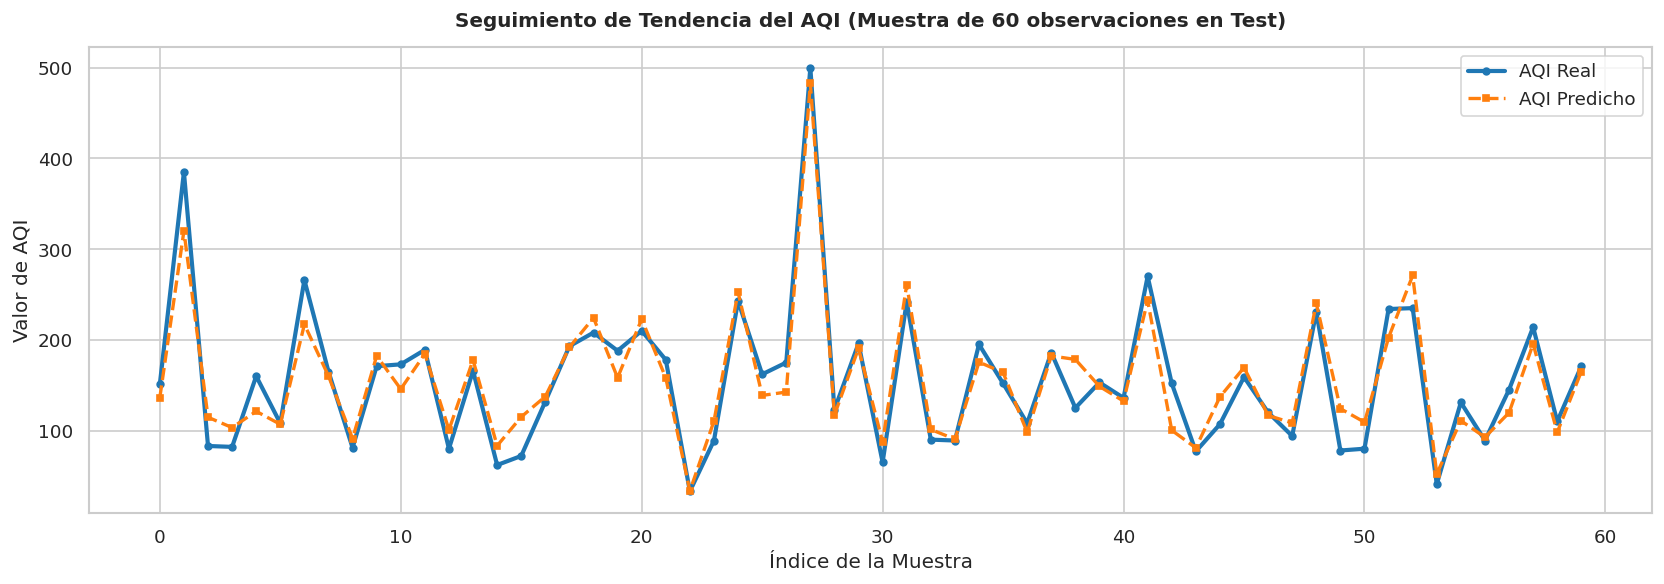

In [32]:
sample_size = 60
y_test_sample = y_test.iloc[:sample_size].values
y_pred_sample = y_pred_test[:sample_size]

plt.figure(figsize=(14, 5))
plt.plot(range(sample_size), y_test_sample, label='AQI Real', color='#1f77b4', linewidth=2.5, marker='o', markersize=4)
plt.plot(range(sample_size), y_pred_sample, label='AQI Predicho', color='#ff7f0e', linewidth=2, linestyle='--', marker='s', markersize=4)
plt.title('Seguimiento de Tendencia del AQI (Muestra de 60 observaciones en Test)', fontweight='bold', pad=12)
plt.xlabel('Índice de la Muestra')
plt.ylabel('Valor de AQI')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

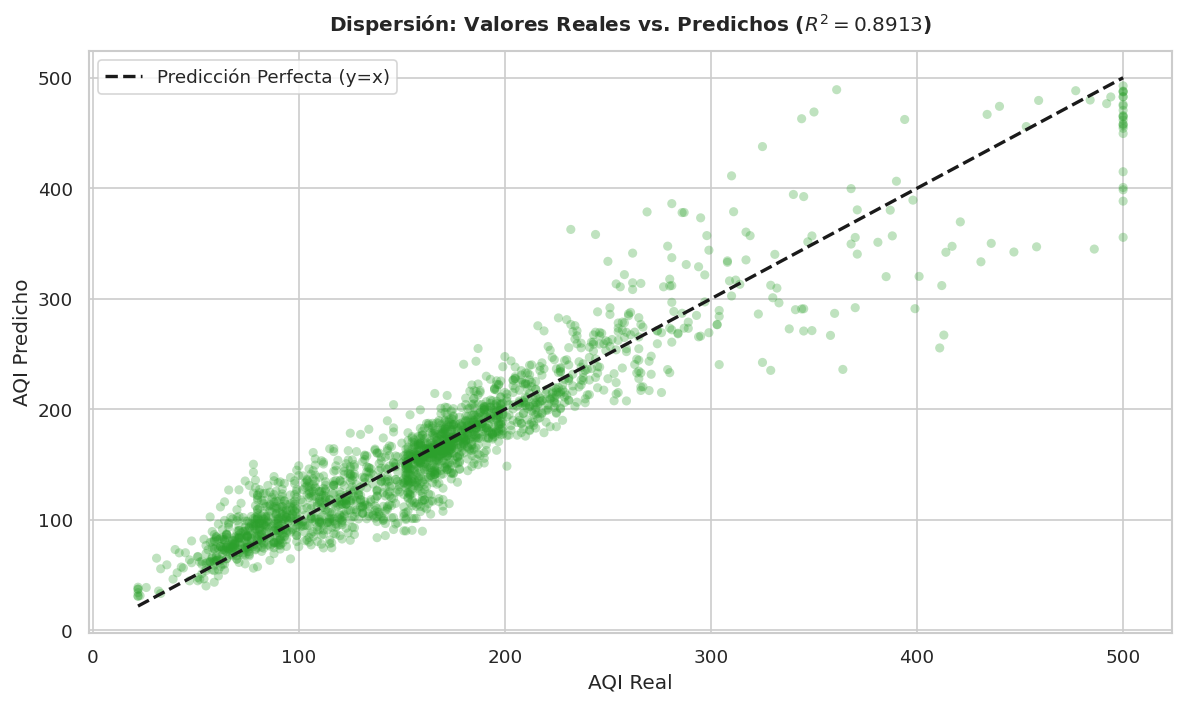

In [33]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_test, alpha=0.3, color='#2ca02c', edgecolors='none', s=30)

max_val = max(y_test.max(), y_pred_test.max())
min_val = min(y_test.min(), y_pred_test.min())
plt.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2, label='Predicción Perfecta (y=x)')

plt.title(f'Dispersión: Valores Reales vs. Predichos ($R^2 = {r2_test:.4f}$)', fontweight='bold', pad=12)
plt.xlabel('AQI Real')
plt.ylabel('AQI Predicho')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

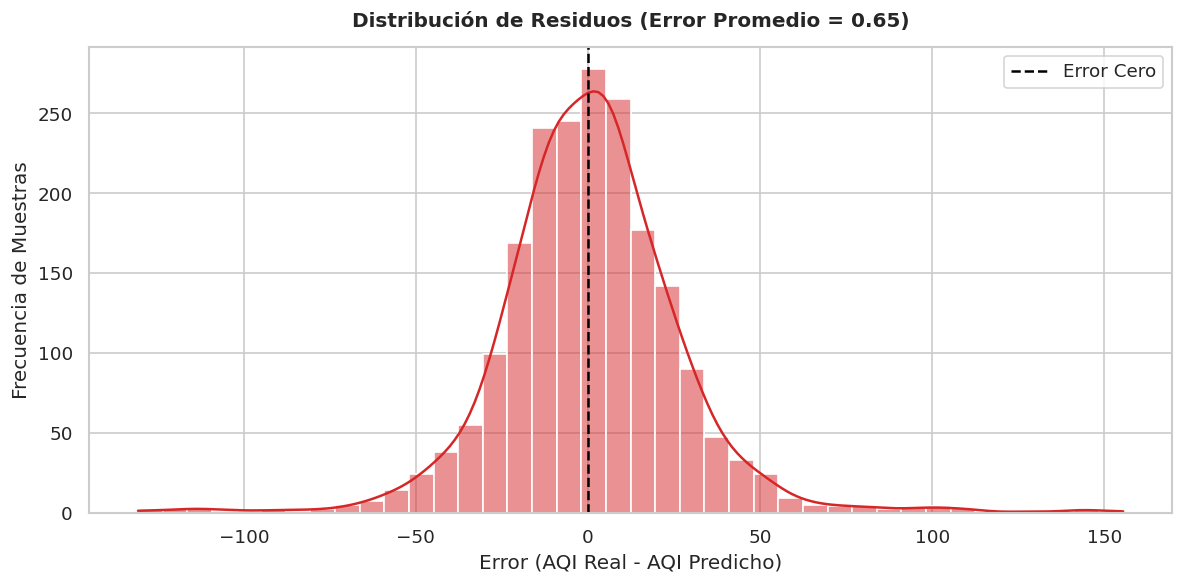

In [34]:
residuals = y_test - y_pred_test

plt.figure(figsize=(10, 5))
sns.histplot(residuals, kde=True, color='#d62728', bins=40)
plt.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Error Cero')
plt.title(f'Distribución de Residuos (Error Promedio = {residuals.mean():.2f})', fontweight='bold', pad=12)
plt.xlabel('Error (AQI Real - AQI Predicho)')
plt.ylabel('Frecuencia de Muestras')
plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_1069/2605349485.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_importances.values, y=feat_importances.index, palette="Blues_r")


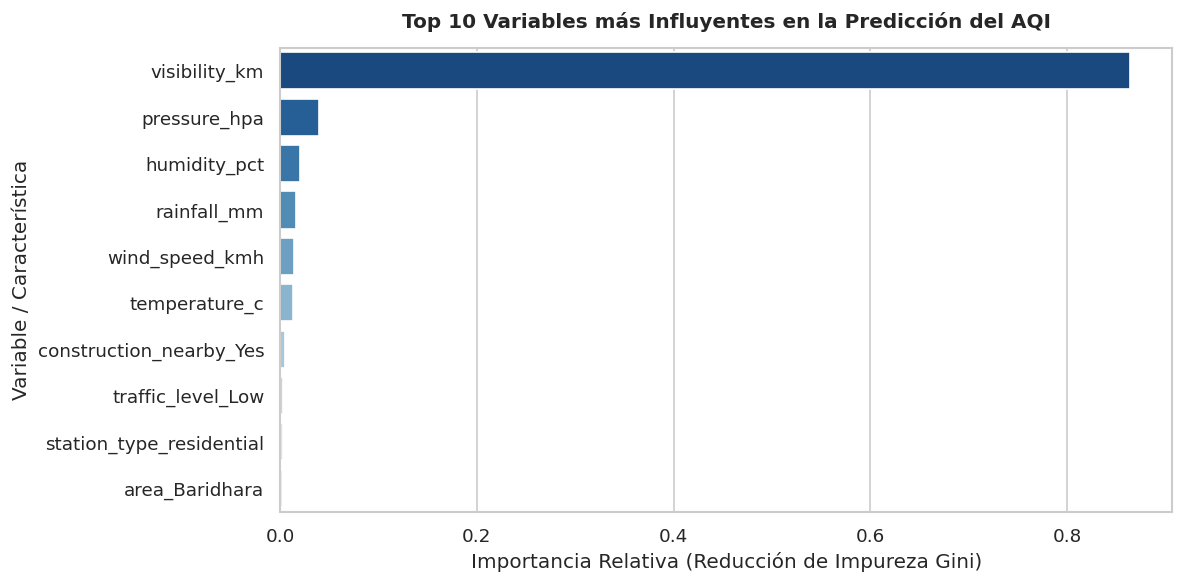

In [35]:
ohe_feature_names = best_rf.named_steps['prep'].named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(ohe_feature_names)

importances = best_rf.named_steps['model'].feature_importances_
feat_importances = pd.Series(importances, index=all_feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=feat_importances.values, y=feat_importances.index, palette="Blues_r")
plt.title('Top 10 Variables más Influyentes en la Predicción del AQI', fontweight='bold', pad=12)
plt.xlabel('Importancia Relativa (Reducción de Impureza Gini)')
plt.ylabel('Variable / Característica')
plt.tight_layout()
plt.show()

##**Red Neuronal Artificial:** Perceptrón Multicapa (MLPRegressor)

In [51]:
pipeline_mlp = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', MLPRegressor(random_state=42, max_iter=500))
])

###Busqueda de los mejores hiperparámetros

In [54]:
param_grid_mlp = {
    'regressor__hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'regressor__activation': ['relu', 'tanh'],
    'regressor__alpha': [0.0001, 0.001, 0.01]  # Regularización L2
}

grid_mlp = GridSearchCV(
    estimator=pipeline_mlp,
    param_grid=param_grid_mlp,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=2
)

grid_mlp.fit(X_train, y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['temperature_c',
                                                                          'humidity_pct',
                                                                          'wind_speed_kmh',
                                                                          'rainfall_mm',
                                                                          'pressure_hpa',
                                                                          'visibility_km']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['area',
                                                                          'station_type',
                                                                          'wind_direction',
                                                                          'traffic_level',
                                                                          'construction_nearby'])])),
                                       ('regressor',
                                        MLPRegressor(max_iter=500,
                                                     random_state=42))]),
             n_jobs=-1,
             param_grid={'regressor__activation': ['relu', 'tanh'],
                         'regressor__alpha': [0.0001, 0.001, 0.01],
                         'regressor__hidden_layer_sizes': [(50,), (100,),
                                                           (50, 50)]},
             scoring='neg_root_mean_squared_error', verbose=2)

###Evaluación y visualización de resultados

In [55]:
best_mlp = grid_mlp.best_estimator_
y_pred_mlp = best_mlp.predict(X_test)

metrics_mlp = {
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_mlp)),
    'MAE': mean_absolute_error(y_test, y_pred_mlp),
    'MedAE': median_absolute_error(y_test, y_pred_mlp),
    'R2': r2_score(y_test, y_pred_mlp)
}

print("=== MEJORES HIPERPARÁMETROS MLP ===")
print(grid_mlp.best_params_)
print("\n=== MÉTRICAS MLP (TEST) ===")
for metric, val in metrics_mlp.items():
    print(f"{metric}: {val:.4f}")

=== MEJORES HIPERPARÁMETROS MLP ===
{'regressor__activation': 'relu', 'regressor__alpha': 0.01, 'regressor__hidden_layer_sizes': (100,)}

=== MÉTRICAS MLP (TEST) ===
RMSE: 25.5659
MAE: 18.7652
MedAE: 14.3825
R2: 0.8952


###Gráficas de resultados

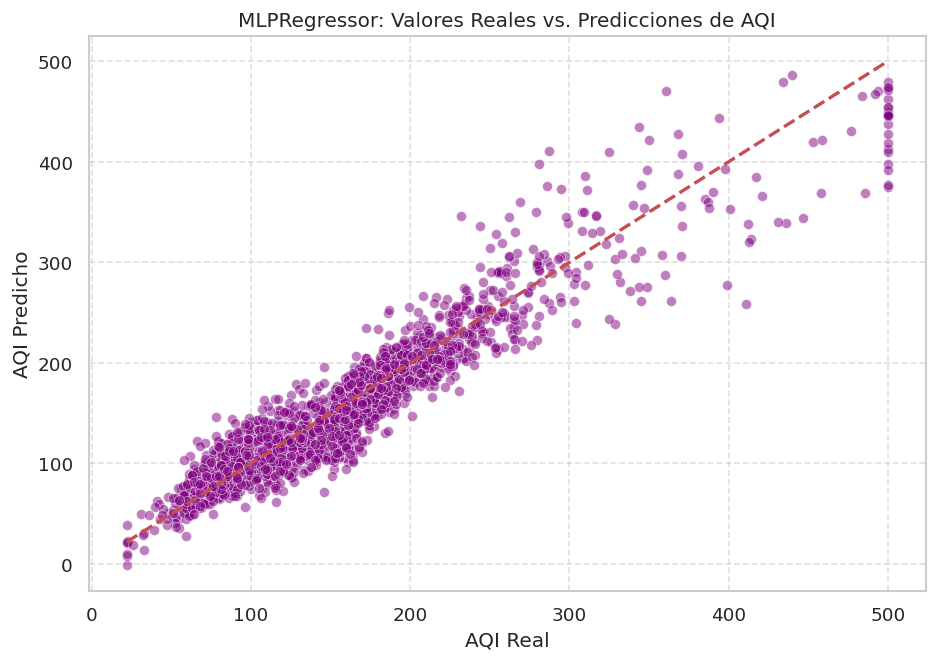

In [56]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=y_test, y=y_pred_mlp, alpha=0.5, color='purple')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('MLPRegressor: Valores Reales vs. Predicciones de AQI')
plt.xlabel('AQI Real')
plt.ylabel('AQI Predicho')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

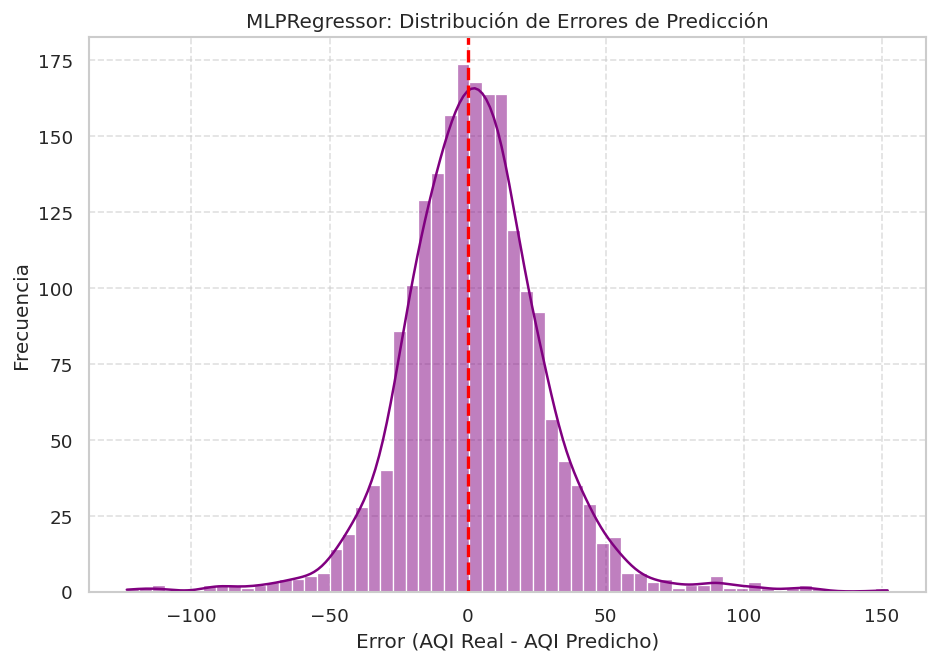

In [57]:
plt.figure(figsize=(9, 6))
residuals_mlp = y_test - y_pred_mlp
sns.histplot(residuals_mlp, kde=True, color='purple')
plt.axvline(0, color='red', linestyle='--', lw=2)
plt.title('MLPRegressor: Distribución de Errores de Predicción')
plt.xlabel('Error (AQI Real - AQI Predicho)')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

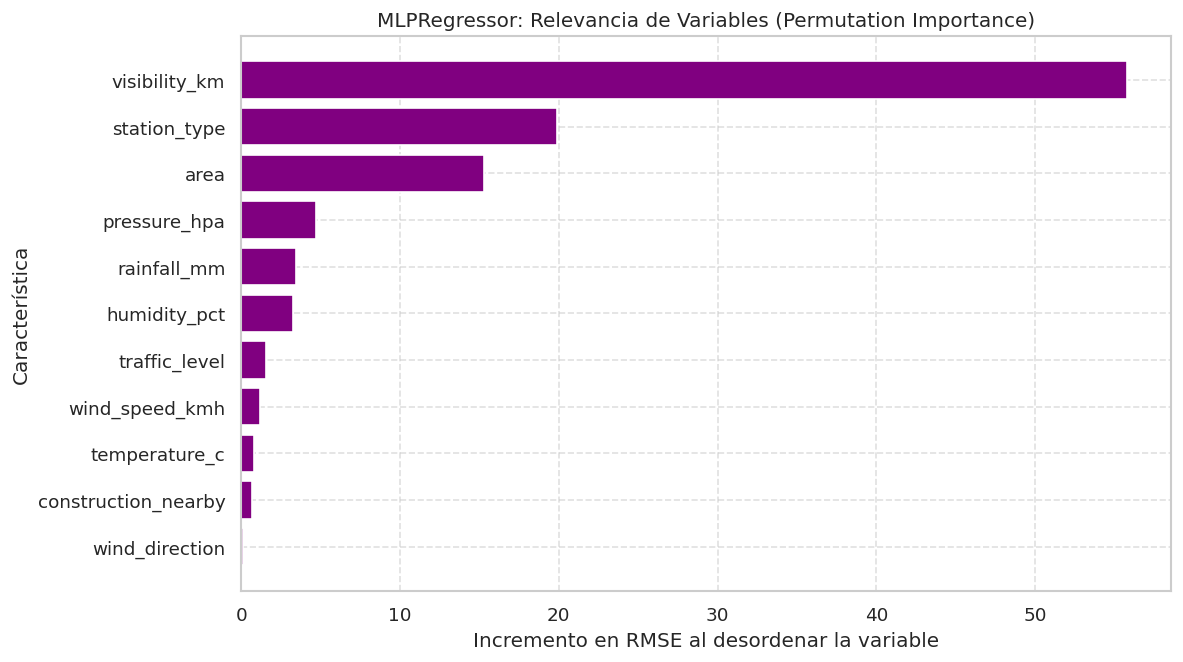

In [58]:
result_mlp = permutation_importance(best_mlp, X_test, y_test, scoring='neg_root_mean_squared_error', n_repeats=10, random_state=42)
sorted_idx_mlp = result_mlp.importances_mean.argsort()

plt.figure(figsize=(10, 6))
plt.barh(X_test.columns[sorted_idx_mlp], result_mlp.importances_mean[sorted_idx_mlp], color='purple')
plt.title('MLPRegressor: Relevancia de Variables (Permutation Importance)')
plt.xlabel('Incremento en RMSE al desordenar la variable')
plt.ylabel('Característica')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

##**Máquina de Vectores de Soporte:** Support Vector Regressor (SVR)

In [59]:
pipeline_svr = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', SVR())
])

###Busqueda de los mejores hiperparámetros

In [65]:
# Malla con escala logarítmica para C y gamma
param_grid_svr = {
    'regressor__kernel': ['rbf', 'linear'],
    'regressor__C': [0.1, 1, 10, 100],
    'regressor__epsilon': [0.01, 0.1, 0.2]
}

grid_svr = GridSearchCV(
    estimator=pipeline_svr,
    param_grid=param_grid_svr,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_svr.fit(X_train, y_train)

GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['temperature_c',
                                                                          'humidity_pct',
                                                                          'wind_speed_kmh',
                                                                          'rainfall_mm',
                                                                          'pressure_hpa',
                                                                          'visibility_km']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['area',
                                                                          'station_type',
                                                                          'wind_direction',
                                                                          'traffic_level',
                                                                          'construction_nearby'])])),
                                       ('regressor', SVR())]),
             n_jobs=-1,
             param_grid={'regressor__C': [0.1, 1, 10, 100],
                         'regressor__epsilon': [0.01, 0.1, 0.2],
                         'regressor__kernel': ['rbf', 'linear']},
             scoring='neg_root_mean_squared_error')

###Evaluación y visualización de resultados

In [66]:
best_svr = grid_svr.best_estimator_
y_pred_svr = best_svr.predict(X_test)

metrics_svr = {
    'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_svr)),
    'MAE': mean_absolute_error(y_test, y_pred_svr),
    'MedAE': median_absolute_error(y_test, y_pred_svr),
    'R2': r2_score(y_test, y_pred_svr)
}

print("=== MEJORES HIPERPARÁMETROS SVR ===")
print(grid_svr.best_params_)
print("\n=== MÉTRICAS SVR (TEST) ===")
for metric, val in metrics_svr.items():
    print(f"{metric}: {val:.4f}")

=== MEJORES HIPERPARÁMETROS SVR ===
{'regressor__C': 100, 'regressor__epsilon': 0.2, 'regressor__kernel': 'rbf'}

=== MÉTRICAS SVR (TEST) ===
RMSE: 26.6499
MAE: 19.0850
MedAE: 14.0316
R2: 0.8861


###Gráficas de resultados

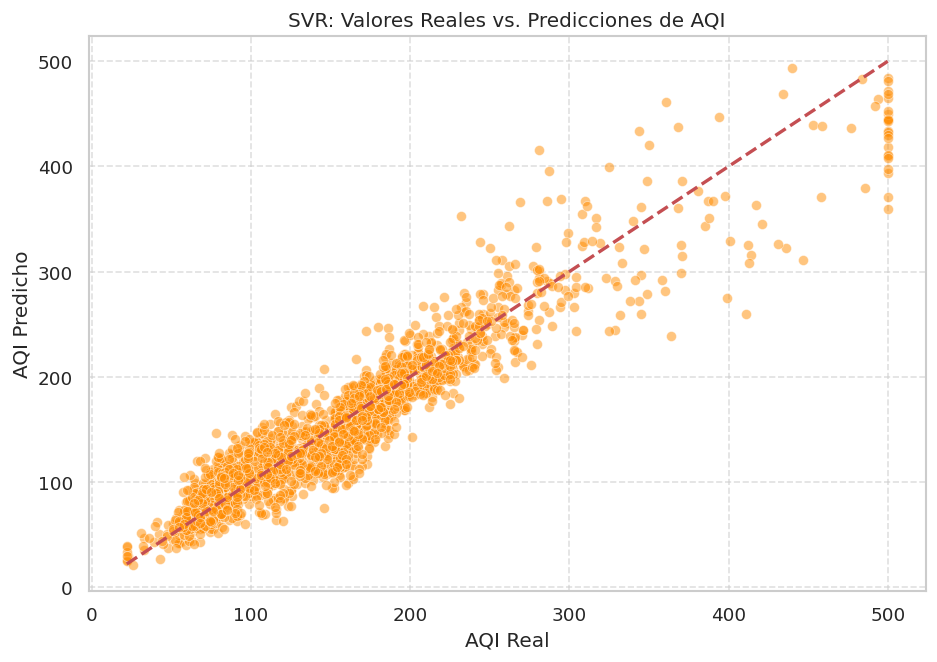

In [62]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=y_test, y=y_pred_svr, alpha=0.5, color='darkorange')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('SVR: Valores Reales vs. Predicciones de AQI')
plt.xlabel('AQI Real')
plt.ylabel('AQI Predicho')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

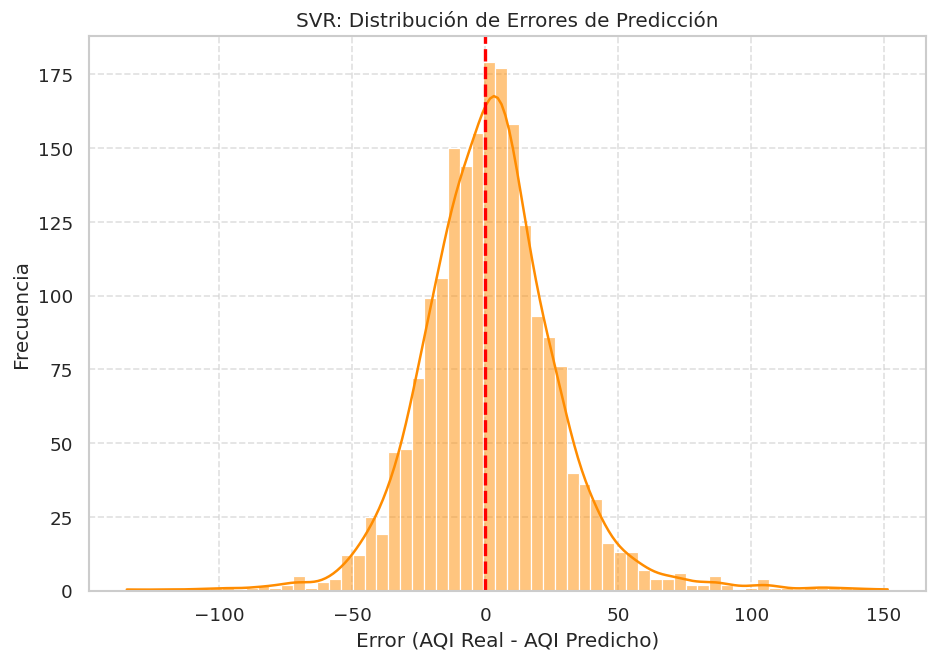

In [63]:
plt.figure(figsize=(9, 6))
residuals_svr = y_test - y_pred_svr
sns.histplot(residuals_svr, kde=True, color='darkorange')
plt.axvline(0, color='red', linestyle='--', lw=2)
plt.title('SVR: Distribución de Errores de Predicción')
plt.xlabel('Error (AQI Real - AQI Predicho)')
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

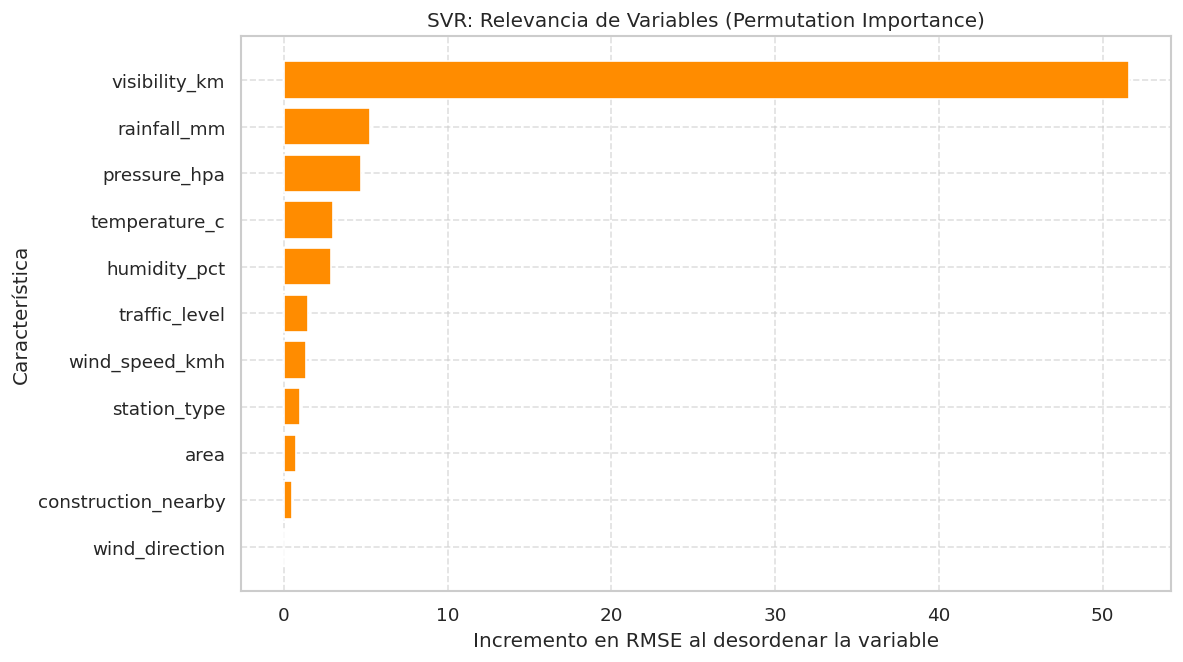

In [64]:
result_svr = permutation_importance(best_svr, X_test, y_test, scoring='neg_root_mean_squared_error', n_repeats=10, random_state=42)
sorted_idx_svr = result_svr.importances_mean.argsort()

plt.figure(figsize=(10, 6))
plt.barh(X_test.columns[sorted_idx_svr], result_svr.importances_mean[sorted_idx_svr], color='darkorange')
plt.title('SVR: Relevancia de Variables (Permutation Importance)')
plt.xlabel('Incremento en RMSE al desordenar la variable')
plt.ylabel('Característica')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()